# Del símbolo a la muestra: canal, ruido y constelación

**Tema 4 · Apartados 4.1–4.3 · Demostración orientativa: 10–20 minutos.**

Ver qué cambia al introducir ganancia, desplazamiento, memoria y ruido, y distinguir las dos componentes del ruido complejo.

## Cómo experimentar
Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno en el navegador.
La descarga .ipynb permite abrirlo en Jupyter o importarlo en Colab.
La vista HTML muestra resultados guardados; no recalcula las gráficas. Los cambios en Colab no modifican el original.
Los datos se generan en el propio cuaderno. La semilla reproduce una realización, no elimina la variabilidad estadística.
No se instalan paquetes ni se descargan datos. Solo se necesitan NumPy y Matplotlib.

## Modelo y pregunta

Los bits se representan por símbolos BPSK: bit 0 → +1 y bit 1 → −1. Fijamos la secuencia repetida
(1, 1, −1, −1) para reconocer fácilmente el efecto del canal. El receptor observa y[n], no el símbolo original.

Comparamos tres modelos, seleccionando uno en los parámetros:
- **Escalar:** y[n] = g x[n] + w[n].
- **Con desplazamiento:** y[n] = g x[n] + b + w[n].
- **Con memoria:** y[n] = g x[n] + a x[n−1] + w[n].

El ruido real tiene media cero y desviación sigma; su potencia es sigma². En el canal con memoria,
x[−1]=0: el paquete empieza sin símbolo anterior. Mostramos N salidas, sin dibujar la cola posterior.
g corresponde a `ganancia`, b a `desplazamiento` y a a `memoria`.
b solo afecta al modelo con desplazamiento; a solo al modelo con memoria.

Después usamos un modelo distinto, **QPSK escalar complejo**, sin desplazamiento ni memoria:
$$x=(\pm1\pm j)/\sqrt2,\quad y=g e^{j\varphi}x+w_I+jw_Q.$$
Cada símbolo tiene energía 1. I y Q del ruido son independientes, de media cero y desviación sigma.
Su potencia total es **2 sigma²**, mientras que en el modelo real anterior era sigma².
La fase phi gira los cuatro centros; el ruido crea nubes alrededor de ellos.
En la ecuación phi está en radianes; el control `fase_grados` se convierte a radianes dentro del código.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
modelo = 'escalar' #@param ['escalar', 'desplazamiento', 'memoria']
ganancia = 0.8 #@param {type:"slider", min:0.2, max:1.5, step:0.1}
desplazamiento = 0.6 #@param {type:"slider", min:-1, max:1, step:0.1}
memoria = 0.6 #@param {type:"slider", min:-1, max:1, step:0.1}
sigma = 0.2 #@param {type:"slider", min:0, max:0.8, step:0.05}
fase_grados = 20 #@param {type:"slider", min:-180, max:180, step:10}
n_simbolos = 40 #@param {type:"integer"}
semilla = 2026 #@param {type:"integer"}
assert modelo in ['escalar','desplazamiento','memoria']
assert .2 <= ganancia <= 1.5 and -1 <= desplazamiento <= 1 and -1 <= memoria <= 1
assert 0 <= sigma <= .8 and -180 <= fase_grados <= 180
assert isinstance(n_simbolos,int) and 20 <= n_simbolos <= 120
assert isinstance(semilla,int) and 0 <= semilla <= 999999

## 1. Seguir los símbolos en el tiempo
La curva «sin ruido» separa el efecto del canal del de una realización de ruido.
Para comparar modelos con el mismo ruido, cambia solo `modelo` y conserva la semilla.
En el modelo con memoria, la muestra puede depender de dos símbolos.

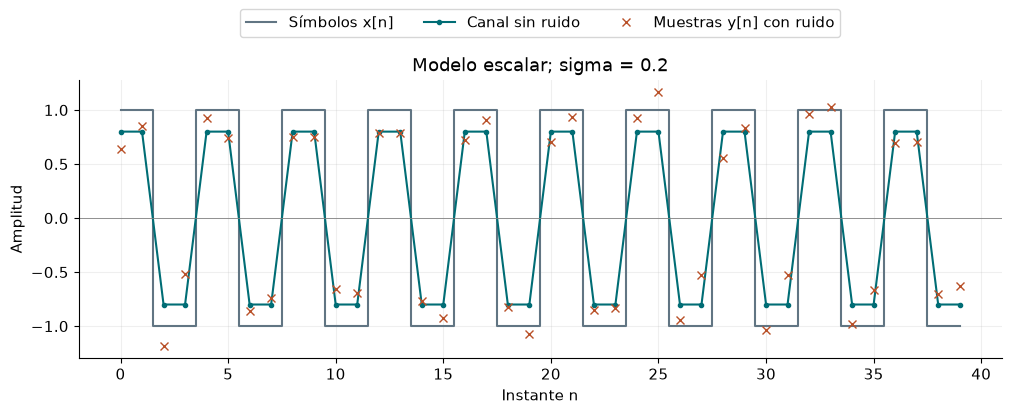

Primeras cuatro salidas sin ruido: [ 0.8  0.8 -0.8 -0.8]
Potencia del ruido real: 0.0400.


In [3]:
x=np.resize(np.array([1.,1.,-1.,-1.]),n_simbolos)
anterior=np.r_[0.,x[:-1]]
sin_ruido=ganancia*x
if modelo=='desplazamiento':sin_ruido=sin_ruido+desplazamiento
if modelo=='memoria':sin_ruido=sin_ruido+memoria*anterior
w=sigma*np.random.default_rng(semilla).standard_normal(n_simbolos)
y=sin_ruido+w
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.step(range(n_simbolos),x,where='mid',label='Símbolos x[n]',color='#617583')
ax.plot(sin_ruido,'-o',ms=3,label='Canal sin ruido',color='#006d75')
ax.plot(y,'x',label='Muestras y[n] con ruido',color='#b95028')
ax.axhline(0,color='gray',lw=.6)
ax.set(xlabel='Instante n',ylabel='Amplitud',title=f'Modelo {modelo}; sigma = {sigma:g}')
ax.legend(loc='upper center',bbox_to_anchor=(.5,1.28),ncol=3);ax.grid(alpha=.2);plt.show()
print('Primeras cuatro salidas sin ruido:',np.round(sin_ruido[:4],3))
print(f'Potencia del ruido real: {sigma**2:.4f}.')

## 2. El mismo concepto en el plano I/Q
Transmitimos 2000 símbolos QPSK por el canal escalar complejo. Las cruces negras son los centros
tras aplicar ganancia y fase. Los círculos grises son los símbolos ideales antes del canal.
La nube es circular porque I y Q tienen igual varianza; una realización finita no es perfectamente simétrica.
`modelo`, b y a de la primera figura **no modifican esta segunda figura**.

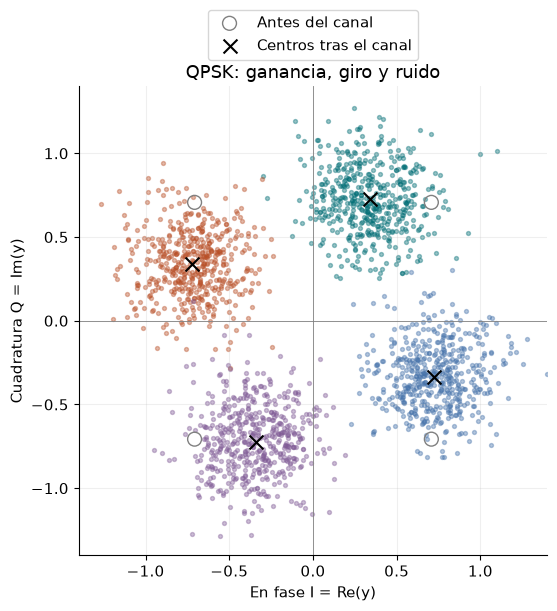

Energía QPSK: 1; potencia útil recibida: 0.6400.
Varianza por componente: 0.0400; potencia total del ruido: 0.0800.


In [4]:
rng_q=np.random.default_rng(semilla+1)
centros_originales=np.array([1+1j,-1+1j,-1-1j,1-1j])/np.sqrt(2)
indices=rng_q.integers(0,4,2000);x_q=centros_originales[indices]
h_q=ganancia*np.exp(1j*np.deg2rad(fase_grados))
w_q=sigma*(rng_q.standard_normal(2000)+1j*rng_q.standard_normal(2000))
y_q=h_q*x_q+w_q;centros=h_q*centros_originales
fig,ax=plt.subplots(figsize=(7,6),layout='constrained')
for k,color in enumerate(['#006d75','#b95028','#805b96','#4572aa']):
    puntos=y_q[indices==k];ax.scatter(puntos.real,puntos.imag,s=8,alpha=.4,color=color)
ax.scatter(centros_originales.real,centros_originales.imag,facecolors='none',edgecolors='gray',s=100,label='Antes del canal')
ax.scatter(centros.real,centros.imag,marker='x',c='black',s=100,label='Centros tras el canal')
limite=max(1.1,ganancia+3*sigma)
ax.set(xlim=(-limite,limite),ylim=(-limite,limite),aspect='equal',xlabel='En fase I = Re(y)',ylabel='Cuadratura Q = Im(y)',title='QPSK: ganancia, giro y ruido')
ax.axhline(0,color='gray',lw=.6);ax.axvline(0,color='gray',lw=.6)
ax.legend(loc='upper center',bbox_to_anchor=(.5,1.18));ax.grid(alpha=.2);plt.show()
print(f'Energía QPSK: 1; potencia útil recibida: {ganancia**2:.4f}.')
print(f'Varianza por componente: {sigma**2:.4f}; potencia total del ruido: {2*sigma**2:.4f}.')

## Antes de mirar la explicación

1. Elige memoria y sigma=0. ¿Por qué los dos símbolos +1 consecutivos no producen siempre la misma salida?
2. En desplazamiento, ¿mover la señal con b aumenta la dispersión del ruido?
3. Cambia sigma de 0.2 a 0.4. ¿Cuánto crece la potencia de ruido?
4. En QPSK, ¿qué cambia al girar 90°? ¿Por qué la potencia compleja no es sigma²?

## Explicación de lo observado

1. Con g=0.8 y a=0.6, las primeras salidas sin ruido son [0.8,1.4,−0.2,−1.4]. La primera usa x[−1]=0;
   las siguientes incluyen el símbolo anterior. Esto es interferencia entre símbolos.
2. No. b mueve el centro; la varianza de w sigue siendo sigma².
3. Se multiplica por cuatro, porque depende del cuadrado de sigma.
4. Giran los centros y permanece la dispersión. Hay dos componentes independientes de potencia sigma²;
   la potencia de su suma compleja es 2 sigma². Las dos partes usan modelos y potencias de ruido diferentes.

## Comprobación del modelo

Contrastamos identidades y casos conocidos; estas comprobaciones no sustituyen la interpretación.

In [5]:
if modelo=='memoria':referencia=np.convolve(x,[ganancia,memoria])[:n_simbolos]
else:referencia=ganancia*x+(desplazamiento if modelo=='desplazamiento' else 0)
assert np.allclose(sin_ruido,referencia) and np.allclose(y-sin_ruido,w)
assert np.allclose(np.abs(centros_originales)**2,1)
assert np.allclose(np.abs(centros)**2,ganancia**2)
assert np.allclose(np.abs(w_q)**2,w_q.real**2+w_q.imag**2)
if sigma==0:assert np.allclose(y_q,h_q*x_q)
print('Convolución, energía QPSK y reparto de potencia comprobados.')

Convolución, energía QPSK y reparto de potencia comprobados.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 4, apartados 4.1–4.3: «Modelo de observación», «Canal con memoria» y «Ruido complejo circular».
- A. Papoulis y S. U. Pillai, *Probability, Random Variables, and Stochastic Processes*: probabilidad, momentos y procesos.
- J. G. Proakis y M. Salehi, *Digital Communications*: modelos de canal y ruido.

Las condiciones y las derivaciones particulares se explican en «Modelo y pregunta».